# Buoy raw data inspection

Explore every raw wave-buoy file under `inputs/Observations/raw/` before/alongside
building the observations catalogue (`03_Generate_Observations_Configuration.ipynb`):
record spans, sampling rate, completeness, directional coverage, and which years/sites
have the most data.

Two networks are combined here:

- **Offshore MHL Waverider buoys** (`raw/buoys/*.nc`) — Manly Hydraulics Laboratory
  deepwater network (Sydney, Port Kembla, Crowdy Head, Coffs Harbour, Byron Bay, Eden,
  Batemans Bay).
- **Nearshore Spotter buoys** (`raw/nearshore_buoys/wave_parameters_netcdf/*.nc`) — NSW
  DCCEEW/SEED nearshore wave buoy program, one file per deployment.

Coordinates and metadata (lon/lat/depth/institution/recording) come from the
observations catalogue built in notebook 03 — run that notebook first.

In [1]:
import calendar
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from utils.config import resolve
from utils.observation import onshore_sites as obs
from utils.viz import case_plots as plot

## 1 · Metadata catalogue

Load instrument metadata from the observations GeoJSON (notebook 03).

In [2]:
meta = (
    obs.get_coordinates()
)  # instrument_id -> lon/lat/type/institution/recording/depth/name
print(f"{len(meta)} instruments in the observations catalogue:\n  {obs.geojson_path()}")

35 instruments in the observations catalogue:
  /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Observations/NewSouthWales_observations.json


## 2 · Discover raw files

Match every raw NetCDF under `inputs/Observations/raw/` to its catalogue
`instrument_id`. Offshore files are named by their 3-letter MHL station code;
nearshore files are named by deployment (case differs from the catalogue, e.g.
`Boomeranga_...` vs `BoomerangA_Buoy`), so the match is case-insensitive.

In [3]:
RAW_DIR = resolve("inputs/Observations/raw")
OFFSHORE_DIR = RAW_DIR / "buoys"
NEARSHORE_DIR = RAW_DIR / "nearshore_buoys" / "wave_parameters_netcdf"

# 3-letter MHL station code -> instrument_id in the observations catalogue
OFFSHORE_CODES = {
    "SYD": "Sydney_Buoy",
    "KEM": "PortKembla_Buoy",
    "CRO": "CrowdyHead_Buoy",
    "COH": "CoffsHarbour_Buoy",
    "BYR": "ByronBay_Buoy",
    "EDE": "Eden_Buoy",
    "BAT": "BatemansBay_Buoy",
}
_meta_lower = {iid.lower(): iid for iid in meta}

file_index: dict[str, dict] = {}
unmatched_files: list[str] = []

for f in sorted(OFFSHORE_DIR.glob("*.nc")):
    iid = OFFSHORE_CODES.get(f.stem.split("_")[0])
    if iid is None:
        unmatched_files.append(f.name)
        continue
    file_index[iid] = {"path": f, "network": "offshore (MHL)"}

for f in sorted(NEARSHORE_DIR.glob("*.nc")):
    candidate = f"{f.stem.split('_')[0]}_buoy"
    iid = _meta_lower.get(candidate.lower())
    if iid is None:
        unmatched_files.append(f.name)
        continue
    file_index[iid] = {"path": f, "network": "nearshore (Spotter)"}

missing_meta = sorted(set(meta) - set(file_index))

print(f"matched {len(file_index)}/{len(meta)} catalogue instruments to a raw file")
print(
    f"  offshore : {sum(v['network'].startswith('offshore') for v in file_index.values())}"
)
print(
    f"  nearshore: {sum(v['network'].startswith('nearshore') for v in file_index.values())}"
)
if unmatched_files:
    print("unmatched raw files:", unmatched_files)
if missing_meta:
    print("catalogue instruments with no raw file found:", missing_meta)

matched 35/35 catalogue instruments to a raw file
  offshore : 7
  nearshore: 28


## 3 · Per-buoy record statistics

For each matched file: record count, start/end, sampling interval, completeness
(records found vs. expected at the median sampling interval over the record span),
available variables, and basic Hs stats.

In [4]:
import xarray as xr


def buoy_stats(path: Path) -> dict:
    ds = xr.open_dataset(path)
    t = ds["time"].values
    n = int(t.size)
    dt_min = (
        float(np.median(np.diff(t)).astype("timedelta64[m]").astype(float))
        if n > 1
        else np.nan
    )
    span_days = float((t[-1] - t[0]) / np.timedelta64(1, "D")) if n > 1 else 0.0
    expected = span_days * 24 * 60 / dt_min if dt_min else np.nan
    completeness = (
        min(100.0, 100.0 * n / expected)
        if expected == expected and expected
        else np.nan
    )

    hs = ds["Hs"].values if "Hs" in ds else np.array([np.nan])
    stats = {
        "n_records": n,
        "start": pd.Timestamp(t[0]),
        "end": pd.Timestamp(t[-1]),
        "span_days": round(span_days, 1),
        "sampling_min": round(dt_min, 1) if dt_min == dt_min else np.nan,
        "completeness_pct": round(completeness, 1)
        if completeness == completeness
        else np.nan,
        "variables": ", ".join(sorted(ds.data_vars)),
        "directional": "Dir" in ds.data_vars,
        "hs_mean": round(float(np.nanmean(hs)), 2),
        "hs_max": round(float(np.nanmax(hs)), 2),
        "hs_nan_pct": round(100.0 * float(np.isnan(hs).mean()), 1),
    }
    ds.close()
    return stats


rows = []
for iid, info in file_index.items():
    row = buoy_stats(info["path"])
    row["instrument_id"] = iid
    row["network"] = info["network"]
    row["name"] = meta[iid].get("name")
    row["depth_m"] = meta[iid].get("depth")
    rows.append(row)

inventory = pd.DataFrame(rows).set_index("instrument_id").sort_values("start")
inventory

,n_records,start,end,span_days,sampling_min,completeness_pct,variables,directional,hs_mean,hs_max,hs_nan_pct,network,name,depth_m
instrument_id,,,,,,,,,,,,,,
CoffsHarbour_Buoy,264380,1976-05-26 11:00:00.000003584,2017-12-31 12:59:59.999996416,15194.1,59.0,71.3,"Dir, Hmax, Hs, Tm02, Tp",True,1.58,7.36,0.0,offshore (MHL),Coffs Harbour offshore Waverider buoy (WAVECOH...,-70.00
ByronBay_Buoy,235446,1976-10-14 05:00:00.000003584,2017-12-31 12:59:59.999996416,15053.3,59.0,64.1,"Dir, Hmax, Hs, Tm02, Tp",True,1.66,7.64,0.0,offshore (MHL),"Byron Bay offshore Waverider buoy (WAVEBYB, BYR)",-65.00
PortKembla_Buoy,261441,1976-10-25 11:00:00.000003584,2017-12-31 12:59:59.999996416,15042.1,59.0,71.2,"Dir, Hmax, Hs, Tm02, Tp",True,1.58,8.43,0.0,offshore (MHL),"Port Kembla offshore Waverider buoy (WAVEPOK, ...",-75.00
CrowdyHead_Buoy,245601,1985-10-09 21:59:59.999996416,2017-12-31 12:59:59.999996416,11770.6,59.0,85.5,"Hmax, Hs, Tm02, Tp",False,1.60,7.35,0.0,offshore (MHL),"Crowdy Head offshore Waverider buoy (WAVECRH, ...",-80.00
BatemansBay_Buoy,233633,1986-05-27 06:00:00.000000000,2015-12-31 12:59:59.999996416,10810.3,59.0,88.5,"Hmax, Hs, Tm02, Tp",False,1.44,7.19,0.0,offshore (MHL),"Batemans Bay offshore Waverider buoy (WAVEBAB,...",-75.00
Sydney_Buoy,190333,1992-03-02 23:00:00.000003584,2017-12-31 12:59:59.999996416,9434.6,59.0,82.7,"Dir, Hmax, Hs, Tm02, Tp",True,1.62,8.43,0.0,offshore (MHL),Sydney offshore Waverider buoy (WAVESYD),-85.00
Eden_Buoy,39623,2012-07-20 00:00:00.000000000,2017-12-31 12:59:59.999996416,1990.5,59.0,81.6,"Dir, Hmax, Hs, Tm02, Tp",True,1.66,8.49,0.0,offshore (MHL),"Eden offshore Waverider buoy (WAVEEDN, EDE)",-100.00
Narrabeen_Buoy,3646,2016-03-01 23:00:00.000000000,2016-05-16 21:30:00.000000000,75.9,30.0,100.0,"Dir, Hmax, Hs, Tm02, Tp",True,0.99,2.46,0.2,nearshore (Spotter),Narrabeen nearshore wave buoy,-12.40
Collaroy_Buoy,3647,2016-03-01 23:30:00.000000000,2016-05-16 22:30:00.000000000,76.0,30.0,100.0,"Dir, Hmax, Hs, Tm02, Tp",True,0.80,1.73,0.1,nearshore (Spotter),Collaroy nearshore wave buoy,-13.17


Save the inventory table for reference.

In [5]:
inventory_path = resolve("outputs/buoys_raw_inventory.csv")
inventory_path.parent.mkdir(parents=True, exist_ok=True)
inventory.to_csv(inventory_path)
print(f"wrote {len(inventory)} rows to {inventory_path}")

wrote 35 rows to /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/outputs/buoys_raw_inventory.csv


## 4 · Record timeline

Each buoy's coverage span, coloured by network.

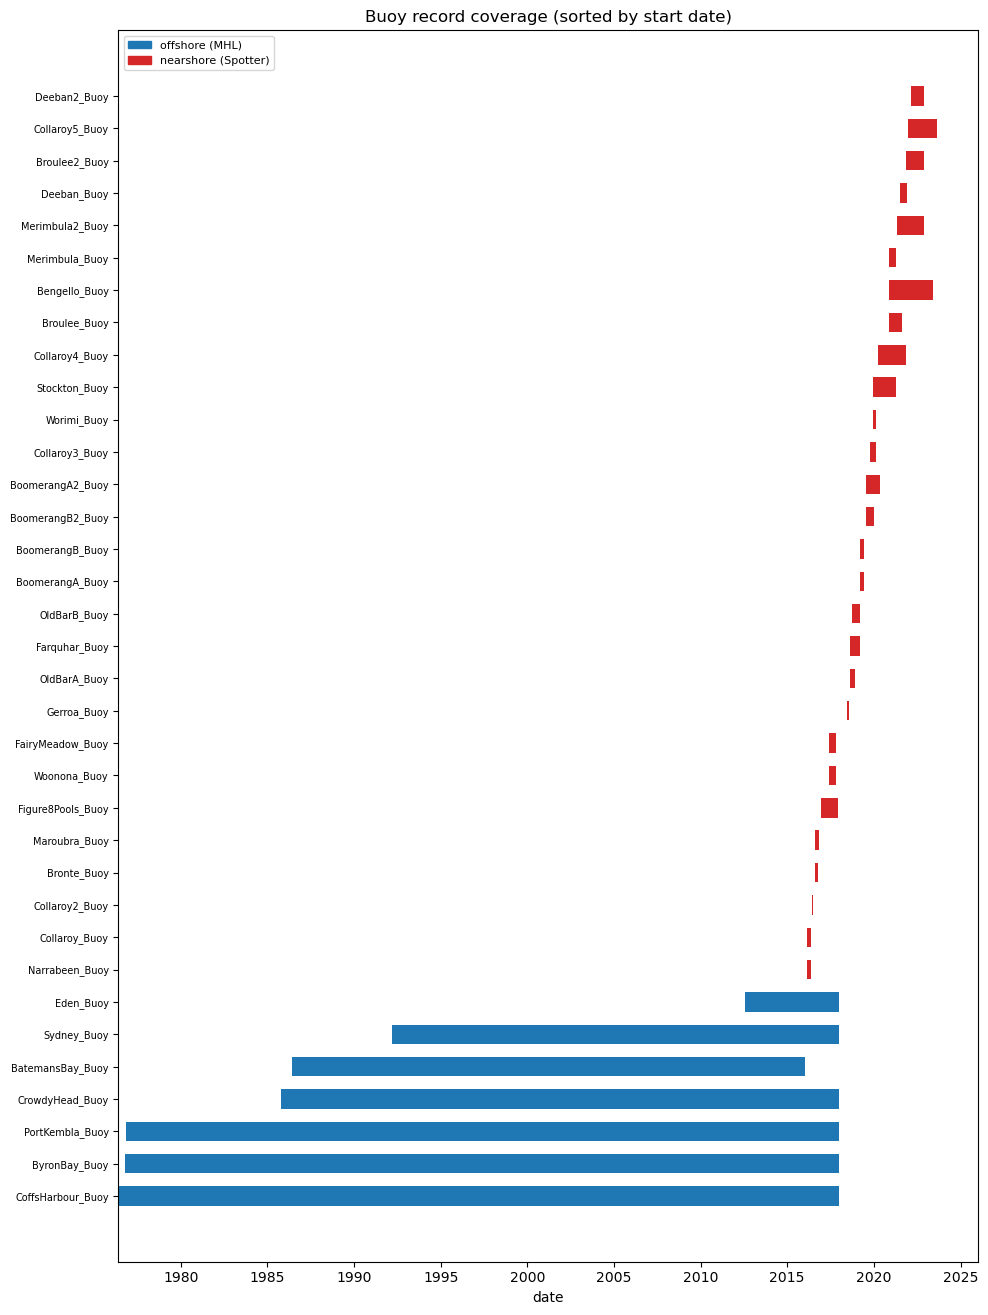

In [6]:
NETWORK_COLORS = {"offshore (MHL)": "#1f77b4", "nearshore (Spotter)": "#d62728"}

fig, ax = plt.subplots(figsize=(10, 0.35 * len(inventory) + 1))
for i, iid in enumerate(inventory.index):
    row = inventory.loc[iid]
    ax.barh(
        i,
        (row["end"] - row["start"]).days,
        left=row["start"],
        height=0.6,
        color=NETWORK_COLORS[row["network"]],
    )
ax.set_yticks(range(len(inventory)))
ax.set_yticklabels(inventory.index, fontsize=7)
ax.set_xlabel("date")
ax.set_title("Buoy record coverage (sorted by start date)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in NETWORK_COLORS.values()]
ax.legend(handles, NETWORK_COLORS.keys(), loc="upper left", fontsize=8)
fig.tight_layout()

## 5 · Data availability by year

Convert each buoy's yearly record count to **data-days** (`n_records × sampling_interval`),
so buoys with different sampling rates (offshore hourly vs. nearshore 30 min) compare fairly.

In [7]:
def yearly_data_days(path: Path, dt_min: float) -> pd.Series:
    ds = xr.open_dataset(path)
    t = pd.DatetimeIndex(ds["time"].values)
    ds.close()
    counts = t.year.value_counts().sort_index()
    return counts * (dt_min / 60.0 / 24.0)


yearly = {
    iid: yearly_data_days(info["path"], inventory.loc[iid, "sampling_min"])
    for iid, info in file_index.items()
}
yearly_df = pd.DataFrame(yearly).fillna(0.0).sort_index()
yearly_df.index.name = "year"
yearly_df

,BatemansBay_Buoy,ByronBay_Buoy,CoffsHarbour_Buoy,CrowdyHead_Buoy,Eden_Buoy,PortKembla_Buoy,Sydney_Buoy,Bengello_Buoy,BoomerangA2_Buoy,BoomerangA_Buoy,...,Gerroa_Buoy,Maroubra_Buoy,Merimbula2_Buoy,Merimbula_Buoy,Narrabeen_Buoy,OldBarA_Buoy,OldBarB_Buoy,Stockton_Buoy,Woonona_Buoy,Worimi_Buoy
year,,,,,,,,,,,,,,,,,,,,,
1976,0.000000,12.578472,35.359028,0.000000,0.000000,6.514583,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000
1977,0.000000,47.240972,53.632639,0.000000,0.000000,26.058333,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000
1978,0.000000,43.184722,51.092361,0.000000,0.000000,54.534028,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000
1979,0.000000,41.873611,46.298611,0.000000,0.000000,48.593056,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000
1980,0.000000,33.597222,49.617361,0.000000,0.000000,49.125694,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000
1981,0.000000,24.583333,44.250000,0.000000,0.000000,54.493056,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000
1982,0.000000,38.718750,50.764583,0.000000,0.000000,52.895139,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000
1983,0.000000,31.548611,47.855556,0.000000,0.000000,46.052778,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000
1984,0.000000,163.643056,168.150000,0.000000,0.000000,215.104167,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000


### Coverage heatmap — % of each calendar year with data, per buoy

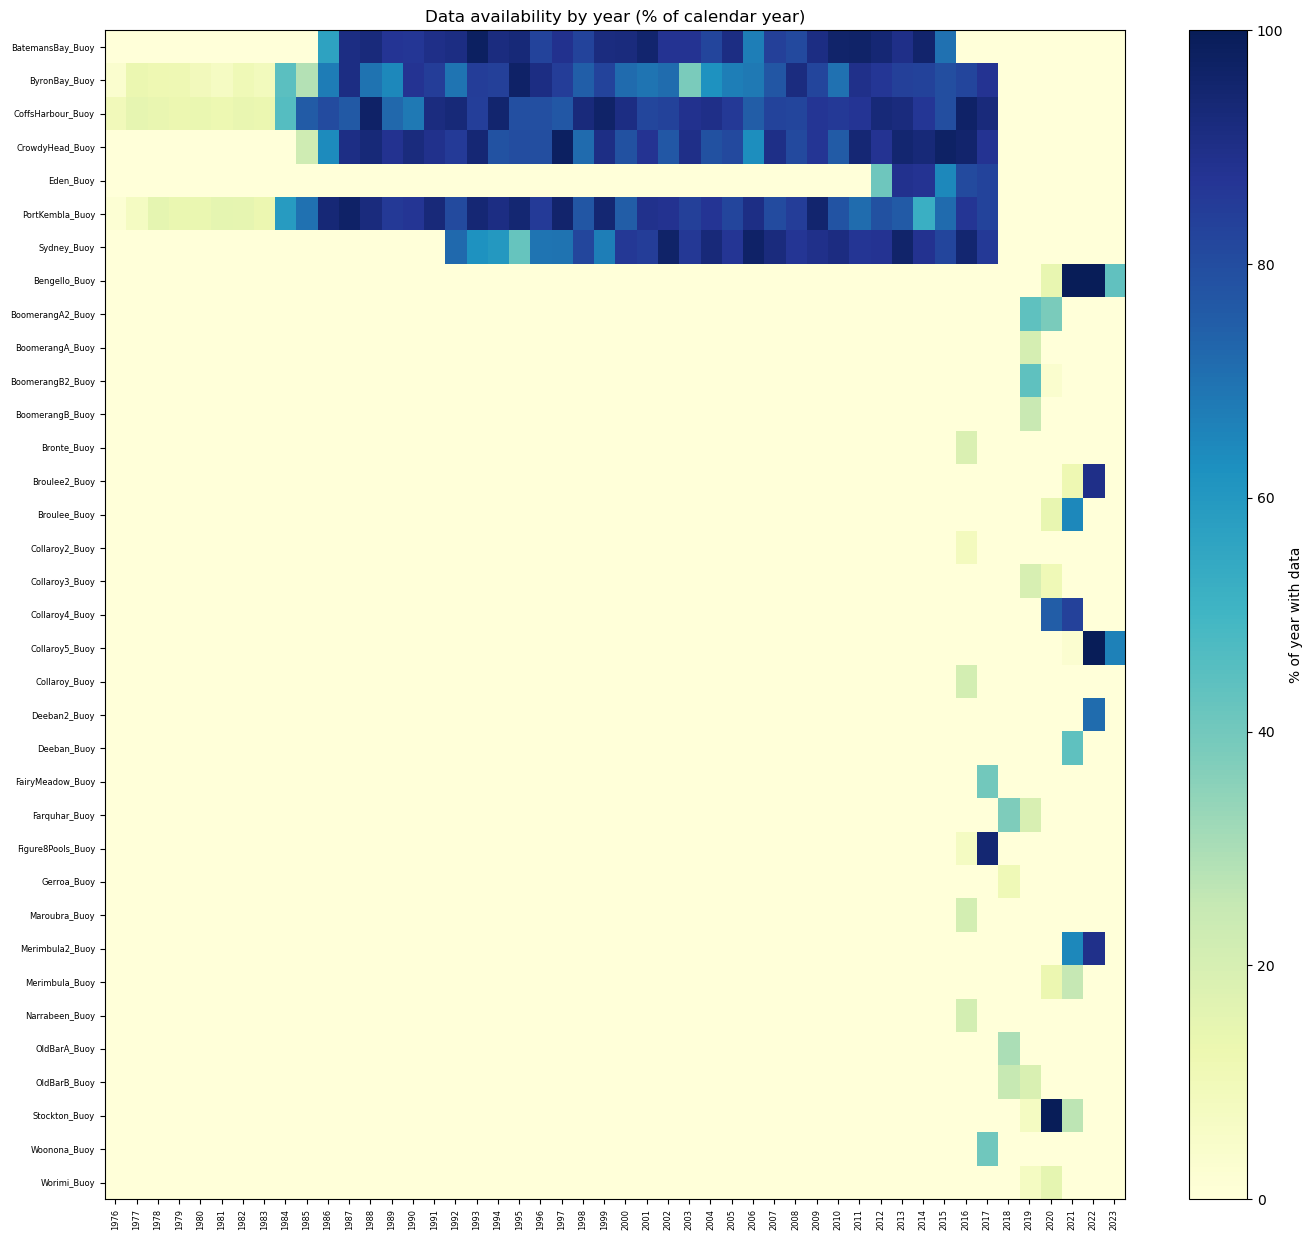

In [8]:
days_in_year = pd.Series(
    {y: 366 if calendar.isleap(y) else 365 for y in yearly_df.index}
)
coverage_pct = yearly_df.div(days_in_year, axis=0).clip(upper=1.0) * 100

fig, ax = plt.subplots(figsize=(14, 0.3 * len(coverage_pct.columns) + 2))
im = ax.imshow(coverage_pct.T.values, aspect="auto", cmap="YlGnBu", vmin=0, vmax=100)
ax.set_yticks(range(len(coverage_pct.columns)))
ax.set_yticklabels(coverage_pct.columns, fontsize=6)
ax.set_xticks(range(len(coverage_pct.index)))
ax.set_xticklabels(coverage_pct.index, rotation=90, fontsize=6)
ax.set_title("Data availability by year (% of calendar year)")
fig.colorbar(im, ax=ax, label="% of year with data")
fig.tight_layout()

### Years with the most data

Total data-days across **all** buoys, per calendar year — useful for picking a
validation/reconstruction `period` with the widest buoy coverage.

Top 10 years by total data-days:
  2017:   2529.9 data-days across 9 buoys
  2016:   2316.2 data-days across 12 buoys
  2013:   2263.8 data-days across 7 buoys
  2014:   2138.5 data-days across 7 buoys
  2012:   2080.8 data-days across 7 buoys
  2015:   1988.8 data-days across 7 buoys
  2009:   1938.4 data-days across 6 buoys
  2011:   1915.4 data-days across 6 buoys
  1999:   1905.0 data-days across 6 buoys
  1993:   1885.2 data-days across 6 buoys


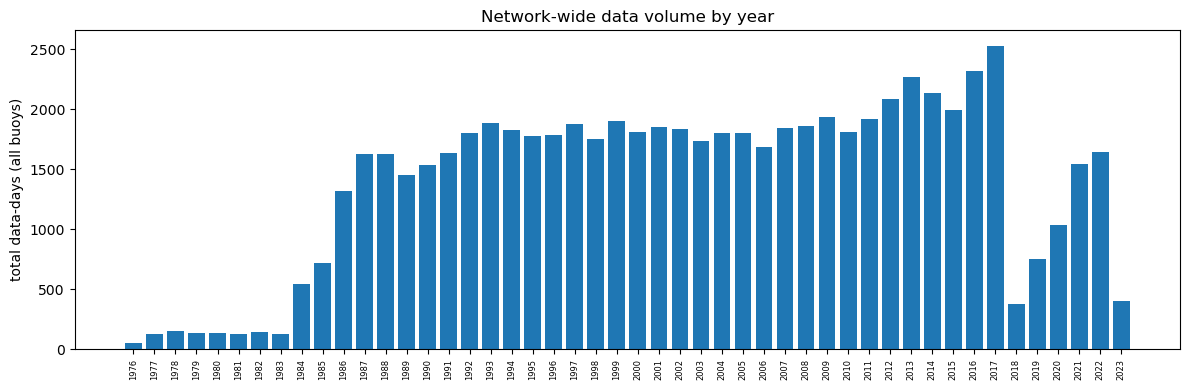

In [9]:
total_per_year = yearly_df.sum(axis=1)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(total_per_year.index.astype(str), total_per_year.values, color="#1f77b4")
ax.set_ylabel("total data-days (all buoys)")
ax.set_title("Network-wide data volume by year")
ax.tick_params(axis="x", rotation=90, labelsize=6)
fig.tight_layout()

print("Top 10 years by total data-days:")
top_years = total_per_year.sort_values(ascending=False).head(10)
for year, days in top_years.items():
    n_buoys = int((yearly_df.loc[year] > 0).sum())
    print(f"  {year}: {days:8.1f} data-days across {n_buoys} buoys")

## 6 · Spatial coverage

All matched buoys, coloured by network.

(<Figure size 900x700 with 2 Axes>,
 <Axes: title={'center': 'NewSouthWales — Buoy raw-data inventory'}, xlabel='longitude', ylabel='latitude'>)

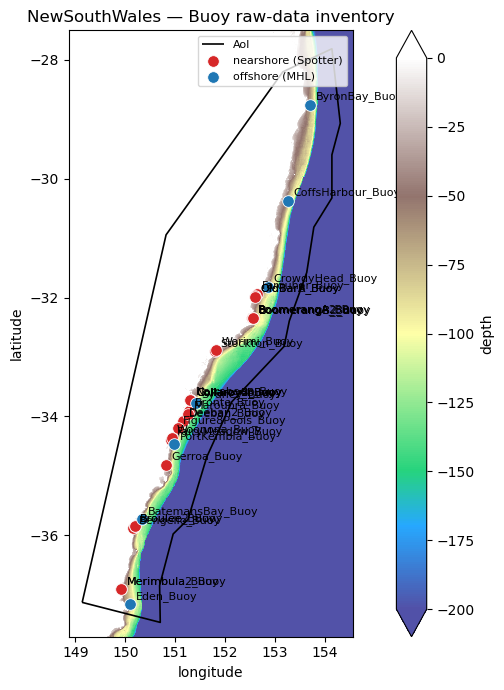

In [10]:
gdf = obs.dict_to_gdf(
    {iid: {**meta[iid], "network": info["network"]} for iid, info in file_index.items()}
)
plot.plot_case_map(
    gdf,
    title="Buoy raw-data inventory",
    color_col="network",
    color_map=NETWORK_COLORS,
)

## 7 · Variable coverage

Which buoys report wave direction (`Dir`), vs. bulk parameters only.

In [11]:
display(inventory[["network", "directional", "variables"]])
print()
print(inventory.groupby("network")["directional"].value_counts())

,network,directional,variables
instrument_id,,,
CoffsHarbour_Buoy,offshore (MHL),True,"Dir, Hmax, Hs, Tm02, Tp"
ByronBay_Buoy,offshore (MHL),True,"Dir, Hmax, Hs, Tm02, Tp"
PortKembla_Buoy,offshore (MHL),True,"Dir, Hmax, Hs, Tm02, Tp"
CrowdyHead_Buoy,offshore (MHL),False,"Hmax, Hs, Tm02, Tp"
BatemansBay_Buoy,offshore (MHL),False,"Hmax, Hs, Tm02, Tp"
Sydney_Buoy,offshore (MHL),True,"Dir, Hmax, Hs, Tm02, Tp"
Eden_Buoy,offshore (MHL),True,"Dir, Hmax, Hs, Tm02, Tp"
Narrabeen_Buoy,nearshore (Spotter),True,"Dir, Hmax, Hs, Tm02, Tp"
Collaroy_Buoy,nearshore (Spotter),True,"Dir, Hmax, Hs, Tm02, Tp"



network              directional
nearshore (Spotter)  True           28
offshore (MHL)       True            5
                     False           2
Name: count, dtype: int64


## 8 · Summary — what we have

In [12]:
n_offshore = (inventory["network"] == "offshore (MHL)").sum()
n_nearshore = (inventory["network"] == "nearshore (Spotter)").sum()
total_instrument_years = yearly_df.sum().sum() / 365.25
longest = inventory["span_days"].idxmax()
most_complete = inventory["completeness_pct"].idxmax()
least_complete = inventory["completeness_pct"].idxmin()
no_dir = inventory.index[~inventory["directional"]].tolist()

print(
    f"Buoys matched          : {len(inventory)} ({n_offshore} offshore, {n_nearshore} nearshore)"
)
print(
    f"Combined record span   : {inventory['start'].min().date()} to {inventory['end'].max().date()}"
)
print(f"Total instrument-years : {total_instrument_years:.1f}")
print(
    f"Busiest year (network) : {int(top_years.index[0])} ({top_years.iloc[0]:.0f} data-days, "
    f"{int((yearly_df.loc[top_years.index[0]] > 0).sum())} buoys)"
)
print(
    f"Longest single record  : {longest} ({inventory.loc[longest, 'span_days']:.0f} days)"
)
print(
    f"Most complete record   : {most_complete} ({inventory.loc[most_complete, 'completeness_pct']:.1f}%)"
)
print(
    f"Least complete record  : {least_complete} ({inventory.loc[least_complete, 'completeness_pct']:.1f}%)"
)
print(f"Non-directional buoys  : {no_dir if no_dir else 'none — all report Dir'}")
print()
print(f"Inventory CSV written to: {inventory_path}")

Buoys matched          : 35 (7 offshore, 28 nearshore)
Combined record span   : 1976-05-26 to 2023-08-30
Total instrument-years : 183.4
Busiest year (network) : 2017 (2530 data-days, 9 buoys)
Longest single record  : CoffsHarbour_Buoy (15194 days)
Most complete record   : Narrabeen_Buoy (100.0%)
Least complete record  : ByronBay_Buoy (64.1%)
Non-directional buoys  : ['CrowdyHead_Buoy', 'BatemansBay_Buoy']

Inventory CSV written to: /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/outputs/buoys_raw_inventory.csv
